# Lottery: Probability of Matching No Winning Numbers

## Counting argument

In [ ]:
import math

total_numbers = 49
winning_numbers = 6
player_numbers = 6

favorable = math.comb(total_numbers - player_numbers, winning_numbers)
possible = math.comb(total_numbers, winning_numbers)

print(favorable, possible, favorable / possible)

6096454 13983816 0.4359649755116915


## Sequential argument

In [ ]:
probability = 1.0
for draw in range(winning_numbers):
    probability *= (total_numbers - player_numbers - draw) / (total_numbers - draw)

print(probability)

0.4359649755116916


## Distribution of the number of matches

In [ ]:
import pandas as pd

matches = list(range(winning_numbers + 1))
pmf = [
    math.comb(player_numbers, k) * math.comb(total_numbers - player_numbers, winning_numbers - k) / possible
    for k in matches
]

distribution = pd.DataFrame({"k": matches, "P(X=k)": pmf})
distribution["1 in"] = 1 / distribution["P(X=k)"]
print(distribution.to_string(index=False))
print("Sum of probabilities:", sum(pmf))

 k       P(X=k)         1 in
 0 4.359650e-01 2.293762e+00
 1 4.130195e-01 2.421193e+00
 2 1.323780e-01 7.554124e+00
 3 1.765040e-02 5.665593e+01
 4 9.686197e-04 1.032397e+03
 5 1.844990e-05 5.420084e+04
 6 7.151124e-08 1.398382e+07
Sum of probabilities: 1.0


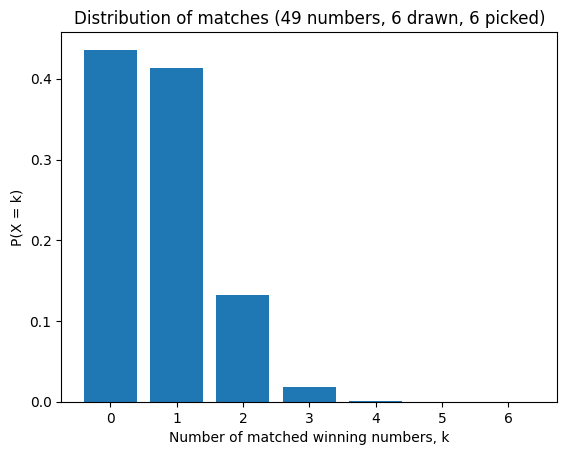

In [ ]:
import matplotlib.pyplot as plt

plt.bar(matches, pmf)
plt.xlabel("Number of matched winning numbers, k")
plt.ylabel("P(X = k)")
plt.title("Distribution of matches (49 numbers, 6 drawn, 6 picked)")
plt.show()

## Expected value and variance

In [ ]:
mean_formula = winning_numbers * player_numbers / total_numbers
variance_formula = (
    winning_numbers * (player_numbers / total_numbers) * (1 - player_numbers / total_numbers)
    * (total_numbers - winning_numbers) / (total_numbers - 1)
)

mean_direct = sum(k * p for k, p in zip(matches, pmf))
variance_direct = sum((k - mean_direct) ** 2 * p for k, p in zip(matches, pmf))

print(mean_formula, mean_direct)
print(variance_formula, variance_direct)

0.7346938775510204 0.7346938775510204
0.5775718450645563 0.5775718450645564


## Simulation check

In [ ]:
import numpy as np

rng = np.random.default_rng(seed=1)
n_games = 100_000
player_pick = np.arange(player_numbers)

counts = np.zeros(winning_numbers + 1)
for _ in range(n_games):
    draw = rng.choice(total_numbers, size=winning_numbers, replace=False)
    counts[np.isin(draw, player_pick).sum()] += 1

simulated = pd.DataFrame({"k": matches, "exact": pmf, "simulated": counts / n_games})
print(simulated.to_string(index=False))

 k        exact  simulated
 0 4.359650e-01    0.43491
 1 4.130195e-01    0.41336
 2 1.323780e-01    0.13407
 3 1.765040e-02    0.01687
 4 9.686197e-04    0.00079
 5 1.844990e-05    0.00000
 6 7.151124e-08    0.00000


# A smaller game: 2 out of 5

## The 10 concrete outcomes

### Outcomes as a matrix

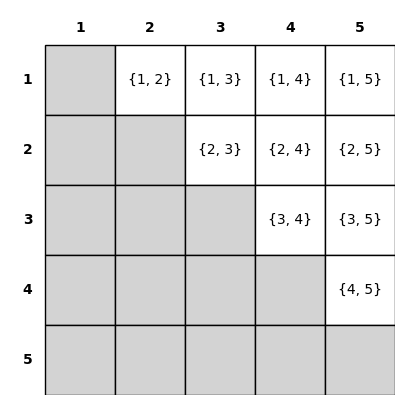

In [ ]:
size = 5

fig, ax = plt.subplots(figsize=(5, 5))
for row in range(1, size + 1):
    for col in range(1, size + 1):
        valid = row < col
        ax.add_patch(plt.Rectangle((col - 1, size - row), 1, 1,
                                   facecolor="white" if valid else "lightgrey",
                                   edgecolor="black"))
        if valid:
            ax.text(col - 0.5, size - row + 0.5, f"{{{row}, {col}}}", ha="center", va="center")

for index in range(1, size + 1):
    ax.text(index - 0.5, size + 0.25, str(index), ha="center", va="center", fontweight="bold")
    ax.text(-0.25, size - index + 0.5, str(index), ha="center", va="center", fontweight="bold")

ax.set_xlim(-0.5, size)
ax.set_ylim(0, size + 0.5)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [ ]:
import itertools

small_total = 5
small_draw = 2
small_picks = 2

small_possible = math.comb(small_total, small_draw)
small_pmf = [
    math.comb(small_picks, k) * math.comb(small_total - small_picks, small_draw - k) / small_possible
    for k in range(small_draw + 1)
]

# Check by listing all 10 possible sets of winning numbers (the player picks {1, 2})
enumerated_counts = [0] * (small_draw + 1)
for winners in itertools.combinations(range(1, small_total + 1), small_draw):
    enumerated_counts[len(set(winners) & {1, 2})] += 1

small_distribution = pd.DataFrame({
    "k": range(small_draw + 1),
    "P(X=k)": small_pmf,
    "enumerated": [count / small_possible for count in enumerated_counts],
})
print(small_distribution.to_string(index=False))

small_mean = sum(k * p for k, p in enumerate(small_pmf))
small_variance = sum((k - small_mean) ** 2 * p for k, p in enumerate(small_pmf))
print(small_mean, small_variance)

 k  P(X=k)  enumerated
 0     0.3         0.3
 1     0.6         0.6
 2     0.1         0.1
0.8 0.36


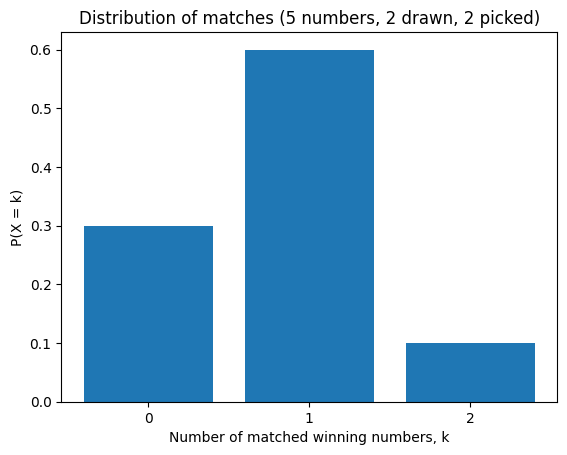

In [ ]:
plt.bar(range(small_draw + 1), small_pmf)
plt.xticks(range(small_draw + 1))
plt.xlabel("Number of matched winning numbers, k")
plt.ylabel("P(X = k)")
plt.title("Distribution of matches (5 numbers, 2 drawn, 2 picked)")
plt.show()

## Simulation check (2 out of 5)

In [ ]:
#ex-class

rng = np.random.default_rng(seed=2)
n_small_games = 100_000

# The numbers chosen by the player are fixed to {1, 2} for this simulation
# Does it matter if the player picks these at random?
# Try updating the code (prompt the gemini agent) or see how the winning numbers are drawn 
# and copy/paste the code.

small_player_pick = np.array([1, 2])

small_counts = np.zeros(small_draw + 1)
for _ in range(n_small_games):
    small_winners = rng.choice(np.arange(1, small_total + 1), size=small_draw, replace=False)
    small_counts[np.isin(small_winners, small_player_pick).sum()] += 1

small_simulated = pd.DataFrame({
    "k": range(small_draw + 1),
    "exact": small_pmf,
    "simulated": small_counts / n_small_games,
})
print(small_simulated.to_string(index=False))

 k  exact  simulated
 0    0.3    0.30163
 1    0.6    0.59851
 2    0.1    0.09986
